# Notebook 2B — Graph Transformers (HGT/GTN) & Clustering Hierarchical Leiden
**Projet** : Cybersécurité & TAL · **Membre 3** · **Chapitre 2** (Transformers & GTN) · TDSP Étape 3 (Modeling / *Threat Mapping*)

**Objectifs**
1. Construire un graphe hétérogène `Document` / `Entité` traçable.
2. Classer les documents avec un Graph Transformer hétérogène (HGT) et le comparer à une baseline texte seul.
3. Regrouper les documents par **Hierarchical Leiden** et cartographier menaces → vecteurs → cibles.
4. Visualiser le graphe enrichi par clusters (PyVis).

**Entrées (livrables du Notebook 1, Walid)** : corpus nettoyé (`corpus_clean.parquet`), thèmes LDA (`df_clean_eda.parquet`), entités du NER (`entities.json`). Tous partagent le même `doc_id`.

**Limites assumées (cf. rapport Business Understanding)**
- Le corpus est un corpus Q/R pédagogique : les clusters sont des *groupes thématiques de documents*, pas des campagnes d'attaque réelles.
- Les entités viennent du NER à règles du Notebook 1 : ce sont des **candidats** non validés manuellement.
- Les labels sont des **pseudo-labels** (thèmes LDA du Notebook 1). Pour limiter la circularité : labels construits sur la colonne `user`, features construites sur la colonne `assistant`.
- Cadre **transductif** : tout le graphe est visible à l'entraînement, seuls les labels val/test sont masqués. Aucun gain n'est garanti : on compare à une baseline.

In [1]:
# Initialisation commune à tous les notebooks du projet : racine du dépôt + package partagé
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from cybersec_nlp import config  # chemins et constantes partagés (data/, artifacts/, reports/)

import os, re, json, random, copy, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import networkx as nx
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from sklearn.metrics import (f1_score, accuracy_score, confusion_matrix,
                             classification_report, normalized_mutual_info_score)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import HGTConv

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = config.ARTIFACTS / "notebook2b"
FIG_DIR = config.REPORTS / "figures"
for directory in (OUT_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Device :", DEVICE)

/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device : cuda


/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 0. Configuration

In [2]:
# --- Données
LABELS_PATH = config.TOPICS_PARQUET       # Notebook 1 : doc_id, user, dominant_topic
ENT_JSON_PATH = config.ENTITIES_JSON      # Notebook 1 : entités du NER par document
N_TOPICS_FALLBACK = 6

# --- Graphe
K_SIM = 5            # voisins SIMILAIRE_A par document
SIM_MIN = 0.35       # similarité cosinus minimale pour créer l'arête
ENT_MIN_DOCS = 2     # une entité doit apparaître dans >= 2 documents
ENT_MAX_FRAC = 0.30  # ... et dans <= 30 % des documents (évite les hubs)

# --- HGT
HIDDEN, HEADS, LAYERS, DROPOUT = 64, 2, 2, 0.5
LR, WD, EPOCHS, PATIENCE = 5e-3, 5e-4, 300, 40

# --- Leiden
MAX_CLUSTER = 40     # taille max d'un cluster feuille
ALPHA_ENT = 0.05     # poids d'une entité partagée dans le graphe de clustering

## 1. Chargement du corpus nettoyé (Notebook 1)

In [3]:
from cybersec_nlp.data.loading import load_clean_corpus

# `corpus_id` = identifiant commun à l'équipe (HF-xxxxx) ; `doc_id` reste l'index entier des nœuds (section 2).
df = load_clean_corpus().rename(columns={"doc_id": "corpus_id"})
print("Corpus nettoyé :", df.shape)
# Les textes sont déjà normalisés (HTML, \\n littéraux, blocs <think>) par le Notebook 1 ;
# on garde les noms de colonnes utilisés dans la suite du notebook.
df["user_txt"], df["assistant_txt"] = df["user"], df["assistant"]

Corpus nettoyé : (2194, 4)


> **Interprétation.** Le corpus nettoyé du Notebook 1 est réutilisé tel quel : **2 194 documents**, avec l'identifiant d'équipe `corpus_id` (HF-xxxxx) pour joindre thèmes et entités ; `doc_id` reste l'index entier des nœuds du graphe.

## 2. Pseudo-labels (thèmes LDA de l'EDA)
Si `df_clean_eda.parquet` est absent, un LDA de secours est calculé sur la colonne `user`.

In [4]:
if os.path.exists(LABELS_PATH):
    lab = pd.read_parquet(LABELS_PATH)[["doc_id", "dominant_topic"]].rename(columns={"doc_id": "corpus_id"})
    df = df.merge(lab, on="corpus_id", how="left")
    n_miss = df["dominant_topic"].isna().sum()
    df = df.dropna(subset=["dominant_topic"]).reset_index(drop=True)
    print(f"Labels EDA chargés ({n_miss} documents sans label retirés)")
else:
    print("Labels EDA absents -> LDA de secours sur la colonne user")
    cv = CountVectorizer(stop_words="english", min_df=5, max_df=0.5)
    Xc = cv.fit_transform(df["user_txt"])
    lda = LatentDirichletAllocation(n_components=N_TOPICS_FALLBACK, random_state=SEED, max_iter=30)
    df["dominant_topic"] = ["Thème %d" % t for t in lda.fit_transform(Xc).argmax(1)]

df["doc_id"] = np.arange(len(df))
classes = sorted(df["dominant_topic"].unique())
cls2id = {c: i for i, c in enumerate(classes)}
y = df["dominant_topic"].map(cls2id).values
N, C = len(df), len(classes)
print(f"{N} documents, {C} classes")
display(df["dominant_topic"].value_counts().to_frame("n"))

Labels EDA chargés (0 documents sans label retirés)
2194 documents, 12 classes


,n
dominant_topic,
T10 · vulnerability / application / exploit,583
T7 · attack / exploit / implementation,271
T1 · attack / implement / session,238
T5 · module / implement / method,218
T2 · detection / implement / evade,191
T9 · process / identify / detect,141
T11 · researcher / analysis / communication,120
T8 · implement / attack / fault,111
T0 · code / network / injection,103


> **Interprétation.** Les pseudo-labels sont les **12 thèmes LDA** retenus par le Notebook 1 (k maximisant la cohérence C_V). Les classes sont déséquilibrées (583 documents pour T10, 56 pour T3) : un modèle qui prédit toujours la classe majoritaire obtient ~27 % d'accuracy et ~0,04 de macro-F1. Ces thèmes étant portés par des mots génériques (Notebook 1, section 8), le score maximal atteignable est limité.

## 3. Entités du NER (Notebook 1)
Les entités viennent de `entities.json` (NER cyber de Walid, aligné STIX 2.1). Leurs labels sont regroupés dans les familles utilisées par la cartographie des menaces : **VECTEUR** (techniques), **MALWARE**, **OUTIL**, **SOFTWARE** (cibles techniques), **CIBLE** (secteurs), **ACTEUR**, **CVE**, **IP**.

In [5]:
def norm_q(s):
    """Question normalisée : sert à grouper les questions identiques dans le même split (section 4)."""
    return re.sub(r"\W+", " ", s.lower()).strip()


FAMILY = {"VECTOR": "VECTEUR", "MALWARE": "MALWARE", "TOOL": "OUTIL", "SOFTWARE": "SOFTWARE", "TARGET": "CIBLE",
          "THREAT_ACTOR": "ACTEUR", "CVE": "CVE", "IP": "IP", "ATTACK_ID": "ATTACK", "HASH": "HASH"}
ner_by_doc = {r["doc_id"]: {(e["key"], FAMILY[e["label"]]) for e in r["entities"]}
              for r in json.load(open(ENT_JSON_PATH, encoding="utf-8"))}
df["entities"] = df["corpus_id"].map(lambda d: ner_by_doc.get(d, set()))

# filtrage des entités trop rares ou trop fréquentes
cnt = Counter(e for s in df["entities"] for e in s)
keep = {e for e, c in cnt.items() if c >= ENT_MIN_DOCS and c <= ENT_MAX_FRAC * N}
ent_list = sorted(keep)
ent2id = {e: i for i, e in enumerate(ent_list)}
M = len(ent_list)
print(f"{M} entités retenues sur {len(cnt)} candidates")
print(Counter(l for _, l in ent_list))
assert M > 0, "Aucune entité retenue : assouplir ENT_MIN_DOCS / ENT_MAX_FRAC"

rows, cols = [], []
for i, s in enumerate(df["entities"]):
    for e in s:
        if e in ent2id:
            rows.append(i); cols.append(ent2id[e])
B = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(N, M))   # Document x Entité
print("Arêtes MENTIONNE :", B.nnz, "| documents sans entité :", int((B.sum(1) == 0).sum()))

198 entités retenues sur 379 candidates
Counter({'SOFTWARE': 55, 'VECTEUR': 43, 'ATTACK': 31, 'OUTIL': 20, 'MALWARE': 18, 'CIBLE': 16, 'CVE': 7, 'IP': 4, 'ACTEUR': 4})
Arêtes MENTIONNE : 4745 | documents sans entité : 387


> **Interprétation.** **198 entités** du NER de Walid sont retenues sur 379 (présentes dans au moins 2 documents et au plus 30 % du corpus) : surtout des logiciels, vecteurs d'attaque, identifiants ATT&CK, outils, malwares et secteurs ciblés. Le graphe couvre **82 % des documents** (387 sans entité retenue) avec 4 745 arêtes `MENTIONNE`, soit ~2,2 entités par document : nettement plus que le lexique initial de ce notebook.

## 4. Features, split et arête SIMILAIRE_A
- Features des documents : TF-IDF de la colonne `assistant` réduit par SVD (les labels viennent de `user`).
- Split **groupé par question normalisée** (70/15/15), aucune fuite de labels.
- `SIMILAIRE_A` est un lien *calculé* (score + méthode), distinct de `MENTIONNE` (lien factuel).

In [6]:
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                        stop_words="english", token_pattern=r"(?u)\b[\w\.\-/+#]{2,}\b")
Xa = tfidf.fit_transform(df["assistant_txt"])
svd = TruncatedSVD(n_components=min(128, Xa.shape[1] - 1), random_state=SEED)
Xd = normalize(svd.fit_transform(Xa))
print("Features documents :", Xd.shape)

# --- split groupé
groups = df["user"].map(norm_q)
ug = groups.unique().copy()
np.random.RandomState(SEED).shuffle(ug)
n1, n2 = int(0.70 * len(ug)), int(0.85 * len(ug))
g_train, g_val, g_test = set(ug[:n1]), set(ug[n1:n2]), set(ug[n2:])
train_mask = groups.isin(g_train).values
val_mask = groups.isin(g_val).values
test_mask = groups.isin(g_test).values
print("train/val/test :", train_mask.sum(), val_mask.sum(), test_mask.sum())

# --- arêtes SIMILAIRE_A (kNN cosinus, non supervisé)
nn_ = NearestNeighbors(n_neighbors=K_SIM + 1, metric="cosine").fit(Xd)
dist, idx = nn_.kneighbors(Xd)
src, dst, w = [], [], []
for i in range(N):
    for d, j in zip(dist[i, 1:], idx[i, 1:]):
        s = 1 - d
        if j != i and s >= SIM_MIN:
            src.append(i); dst.append(j); w.append(s)
S = sp.coo_matrix((w, (src, dst)), shape=(N, N)).tocsr()
S = S.maximum(S.T)                       # symétrisation
print("Arêtes SIMILAIRE_A (non orientées) :", S.nnz // 2)

Features documents : (2194, 128)
train/val/test : 1535 329 330
Arêtes SIMILAIRE_A (non orientées) : 7854


> **Interprétation.** Split groupé 70/15/15 (1 535 / 329 / 330) : une même question ne peut pas se retrouver en entraînement et en test. Les 7 854 arêtes `SIMILAIRE_A` donnent ~7 voisins par document ; ce sont des liens **calculés** (cosinus), distincts des liens factuels `MENTIONNE`.

## 5. Graphe hétérogène (format PyG)

In [7]:
Bc = B.tocoo()
d2e = torch.tensor(np.vstack([Bc.row, Bc.col]), dtype=torch.long)
Sc = S.tocoo()
d2d = torch.tensor(np.vstack([Sc.row, Sc.col]), dtype=torch.long)

x_dict = {
    "doc": torch.tensor(Xd, dtype=torch.float),
    "ent": torch.arange(M, dtype=torch.long),      # indices -> nn.Embedding
}
EDGES_ALL = {
    ("doc", "mentionne", "ent"): d2e,
    ("ent", "mentionne_par", "doc"): d2e.flip(0),
    ("doc", "similaire", "doc"): d2d,
}
y_t = torch.tensor(y, dtype=torch.long)
masks = {k: torch.tensor(v) for k, v in
         {"train": train_mask, "val": val_mask, "test": test_mask}.items()}
print({k: v.shape[1] for k, v in EDGES_ALL.items()})

{('doc', 'mentionne', 'ent'): 4745, ('ent', 'mentionne_par', 'doc'): 4745, ('doc', 'similaire', 'doc'): 15708}


> **Interprétation.** Le graphe hétérogène a 2 types de nœuds (2 194 documents, 198 entités) et 3 types d'arêtes. Les entités fréquentes sont des **hubs** (*windows* : 458 documents, *http* : 365) qui relient beaucoup de documents sans rapport thématique.

## 6. Baseline texte seul
Mêmes features, mêmes splits. Toute comparaison avec le graphe se fait sur ce protocole.

In [8]:
clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0)
clf.fit(Xd[train_mask], y[train_mask])
pred_lr = clf.predict(Xd[test_mask])
res = {}
res["Baseline TF-IDF+SVD + LogReg"] = dict(
    macro_f1=f1_score(y[test_mask], pred_lr, average="macro"),
    acc=accuracy_score(y[test_mask], pred_lr))
print(res)

{'Baseline TF-IDF+SVD + LogReg': {'macro_f1': 0.3167363138821643, 'acc': 0.36363636363636365}}


> **Interprétation.** La baseline texte seul atteint **0,317 de macro-F1** (accuracy 0,364), très au-dessus du hasard (~0,04) : le texte des réponses contient déjà l'essentiel du signal. C'est la référence que le graphe doit battre.

## 7. Graph Transformer hétérogène (HGT)
`HGTConv` applique une attention multi-têtes dépendante du **type de nœud et du type d'arête** : c'est le Graph Transformer hétérogène de PyG (le GTN original de Yun et al. n'y est pas fourni ; à préciser dans le rapport).
Ablation : entités seules vs entités + similarité.

In [9]:
class HGTClassifier(nn.Module):
    def __init__(self, metadata, in_dim, n_ent, n_cls):
        super().__init__()
        self.doc_lin = nn.Linear(in_dim, HIDDEN)
        self.ent_emb = nn.Embedding(n_ent, HIDDEN)
        self.convs = nn.ModuleList([HGTConv(HIDDEN, HIDDEN, metadata, HEADS) for _ in range(LAYERS)])
        self.cls = nn.Linear(HIDDEN, n_cls)

    def embed(self, x_dict, edge_index_dict):
        h = {"doc": F.relu(self.doc_lin(x_dict["doc"])), "ent": self.ent_emb(x_dict["ent"])}
        for conv in self.convs:
            out = conv(h, edge_index_dict)
            h = {k: F.dropout(F.relu(out[k]) if out.get(k) is not None else h[k],
                              p=DROPOUT, training=self.training) for k in h}
        return h["doc"]

    def forward(self, x_dict, edge_index_dict):
        return self.cls(self.embed(x_dict, edge_index_dict))


def train_hgt(edge_keys, name, seed=SEED, masks_=None, record=True):
    torch.manual_seed(seed)
    m_cpu = masks_ if masks_ is not None else masks
    tr_np, te_np = m_cpu["train"].numpy(), m_cpu["test"].numpy()
    ei = {k: EDGES_ALL[k].to(DEVICE) for k in edge_keys}
    xd = {k: v.to(DEVICE) for k, v in x_dict.items()}
    metadata = (["doc", "ent"], list(ei.keys()))
    model = HGTClassifier(metadata, xd["doc"].shape[1], M, C).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    cw = torch.tensor(len(y[tr_np]) / (C * np.bincount(y[tr_np], minlength=C).clip(1)),
                      dtype=torch.float, device=DEVICE)
    yt = y_t.to(DEVICE)
    mk = {k: v.to(DEVICE) for k, v in m_cpu.items()}
    best, best_state, wait, hist = -1, None, 0, []
    for ep in range(EPOCHS):
        model.train(); opt.zero_grad()
        out = model(xd, ei)
        loss = F.cross_entropy(out[mk["train"]], yt[mk["train"]], weight=cw)
        loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pr = model(xd, ei).argmax(1)
        vf1 = f1_score(yt[mk["val"]].cpu(), pr[mk["val"]].cpu(), average="macro")
        hist.append((ep, loss.item(), vf1))
        if vf1 > best:
            best, best_state, wait = vf1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        logits = model(xd, ei)
        emb = model.embed(xd, ei)
    pr = logits.argmax(1).cpu().numpy()
    if record:
        res[name] = dict(macro_f1=f1_score(y[te_np], pr[te_np], average="macro"),
                         acc=accuracy_score(y[te_np], pr[te_np]), best_val_f1=best)
    return model, pr, emb.cpu().numpy(), pd.DataFrame(hist, columns=["epoch", "loss", "val_macro_f1"])


E_ONLY = [("doc", "mentionne", "ent"), ("ent", "mentionne_par", "doc")]
_, _, _, _ = train_hgt(E_ONLY, "HGT (entités seules)")
model, pred_hgt, emb_doc, hist = train_hgt(list(EDGES_ALL.keys()), "HGT (entités + similarité)")

display(pd.DataFrame(res).T.round(3))

,macro_f1,acc,best_val_f1
Baseline TF-IDF+SVD + LogReg,0.317,0.364,NaN
HGT (entités seules),0.147,0.188,0.222
HGT (entités + similarité),0.213,0.227,0.214


> **Interprétation.** Sur ce split, HGT reste **sous la baseline** : 0,147 (entités seules) et 0,213 (entités + similarité) contre 0,317. Ajouter les arêtes de similarité aide nettement le modèle, mais pas assez. La conclusion se fait sur la section 7b (5 découpages).

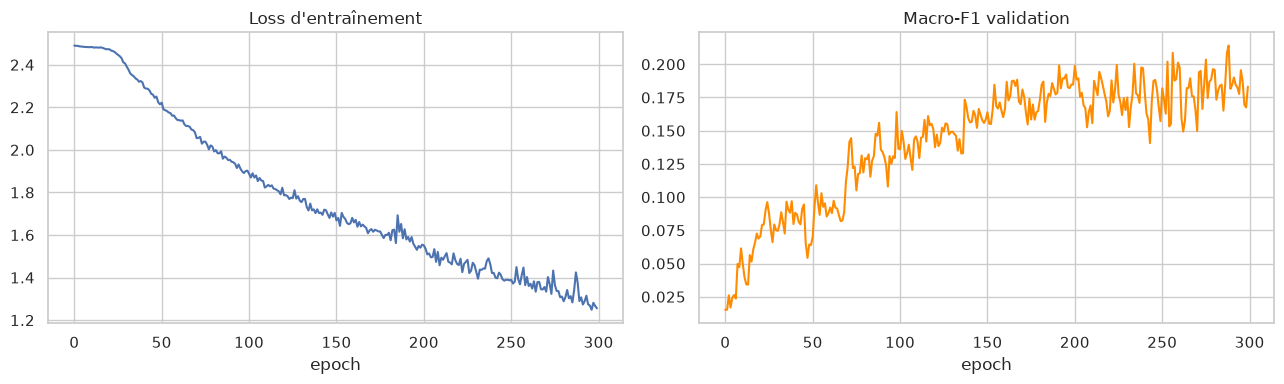

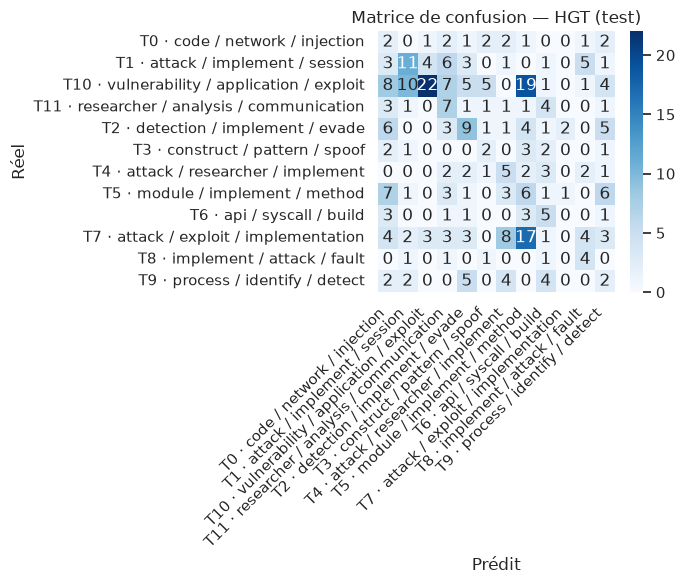

                                             precision    recall  f1-score   support

            T0 · code / network / injection       0.05      0.14      0.07        14
          T1 · attack / implement / session       0.38      0.31      0.34        35
T10 · vulnerability / application / exploit       0.73      0.27      0.39        82
T11 · researcher / analysis / communication       0.20      0.35      0.25        20
         T2 · detection / implement / evade       0.29      0.28      0.29        32
           T3 · construct / pattern / spoof       0.15      0.18      0.17        11
       T4 · attack / researcher / implement       0.20      0.28      0.23        18
           T5 · module / implement / method       0.11      0.21      0.14        29
                 T6 · api / syscall / build       0.21      0.36      0.26        14
     T7 · attack / exploit / implementation       0.00      0.00      0.00        48
            T8 · implement / attack / fault       0.24      0.50

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist["epoch"], hist["loss"]); ax[0].set_title("Loss d'entraînement"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_macro_f1"], color="darkorange"); ax[1].set_title("Macro-F1 validation"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y[test_mask], pred_hgt[test_mask], labels=range(C))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Matrice de confusion — HGT (test)"); plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
print(classification_report(y[test_mask], pred_hgt[test_mask], target_names=classes, zero_division=0))

> **Interprétation.** La perte d'entraînement baisse mais la macro-F1 de validation plafonne vite (~0,21) : le modèle sur-apprend la structure sans généraliser. La matrice de confusion montre des prédictions dispersées ; T10 (vulnérabilités applicatives) est prédit avec une bonne précision (0,73) mais un faible rappel, et T7 n'est jamais reconnu : les thèmes LDA voisins (« attack / exploit / implementation ») se recouvrent.

## 7b. Robustesse : 5 découpages / initialisations
Avec ~360 documents de test, un seul run est fragile. Chaque seed change le split (groupé) et l'initialisation du modèle. Résultat à rapporter : moyenne ± écart-type.

seed 0 terminé


seed 1 terminé


seed 2 terminé


seed 3 terminé


seed 4 terminé


,mean,std
modèle,,
Baseline TF-IDF+SVD + LogReg,0.322,0.023
HGT (entités + similarité),0.183,0.015
HGT (entités seules),0.158,0.011


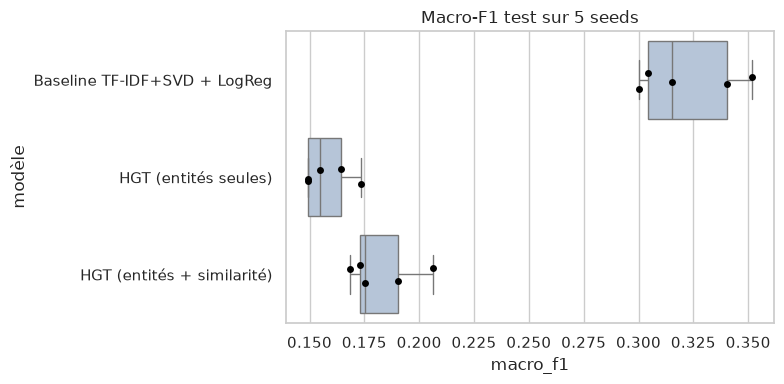

In [11]:
SEEDS = [0, 1, 2, 3, 4]

def make_masks(seed):
    ug_ = groups.unique().copy()
    np.random.RandomState(seed).shuffle(ug_)
    a, b = int(0.70 * len(ug_)), int(0.85 * len(ug_))
    return {"train": groups.isin(set(ug_[:a])).values,
            "val": groups.isin(set(ug_[a:b])).values,
            "test": groups.isin(set(ug_[b:])).values}

VARIANTS = {"HGT (entités seules)": E_ONLY,
            "HGT (entités + similarité)": list(EDGES_ALL.keys())}
runs = []
for s in SEEDS:
    mnp = make_masks(s)
    mt = {k: torch.tensor(v) for k, v in mnp.items()}
    lr_ = LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0).fit(Xd[mnp["train"]], y[mnp["train"]])
    runs.append(("Baseline TF-IDF+SVD + LogReg", s,
                 f1_score(y[mnp["test"]], lr_.predict(Xd[mnp["test"]]), average="macro")))
    for name, keys in VARIANTS.items():
        _, pr_, _, _ = train_hgt(keys, name, seed=s, masks_=mt, record=False)
        runs.append((name, s, f1_score(y[mnp["test"]], pr_[mnp["test"]], average="macro")))
    print("seed", s, "terminé")

runs_df = pd.DataFrame(runs, columns=["modèle", "seed", "macro_f1"])
summary = runs_df.groupby("modèle")["macro_f1"].agg(["mean", "std"]).round(3)
display(summary)
plt.figure(figsize=(8, 4))
sns.boxplot(data=runs_df, x="macro_f1", y="modèle", color="lightsteelblue")
sns.stripplot(data=runs_df, x="macro_f1", y="modèle", color="black", size=5)
plt.title("Macro-F1 test sur 5 seeds"); plt.tight_layout(); plt.show()

> **Interprétation.** Sur 5 découpages, la baseline obtient **0,322 ± 0,023** contre **0,183 ± 0,015** pour HGT (entités + similarité) et 0,158 ± 0,011 (entités seules). L'écart (~0,14) est six fois plus grand que la variabilité : **le graphe n'apporte pas de gain** pour ces pseudo-labels. C'est cohérent avec le Notebook 2A (GCN/GAT sous TF-IDF) : sur ce corpus, la catégorie d'un document dépend de son texte, pas de ses voisins.

## 7c. Influence des entités sur les prédictions (occlusion)
`HGTConv` n'expose pas ses poids d'attention. Pour montrer quelles entités pèsent sur le modèle, on **retire une entité du graphe** (toutes ses arêtes) et on mesure le changement de distribution prédite des documents (variation totale, entre 0 et 1) :
- documents qui **mentionnent** l'entité (effet direct) ;
- documents qui **ne la mentionnent pas** (effet **non local**, par propagation via entités et similarités).

,entité,type,docs,effet direct,effet non local,prédictions changées
97,http,SOFTWARE,365,0.1628,0.0414,212
142,privilege escalation,VECTEUR,229,0.2018,0.0292,151
190,windows,SOFTWARE,458,0.1106,0.0277,177
178,tls,SOFTWARE,103,0.2925,0.0241,123
56,buffer overflow,VECTEUR,133,0.1365,0.0186,86
158,side-channel,VECTEUR,106,0.3028,0.0171,111
112,lateral movement,VECTEUR,94,0.1928,0.0169,89
52,banking,CIBLE,38,0.3579,0.0167,73
85,exchange,SOFTWARE,87,0.1721,0.0163,71
150,remote code execution,VECTEUR,96,0.1538,0.0153,94


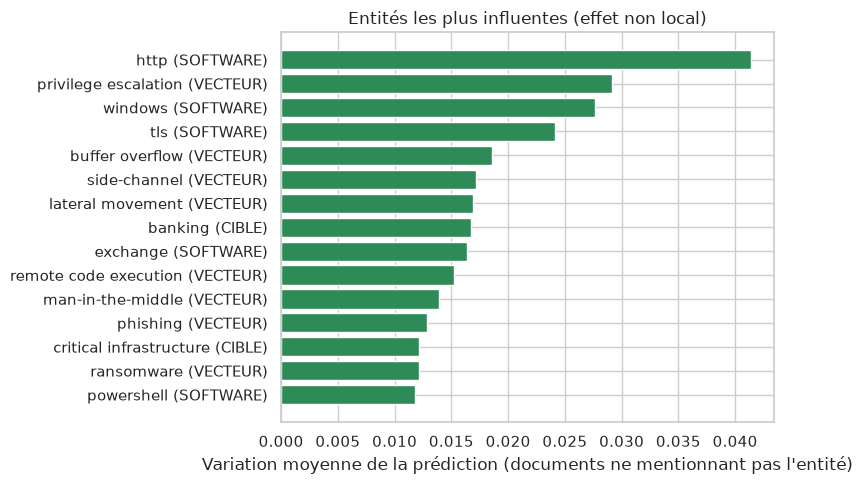

In [12]:
model.eval()
ei_full = {k: v.to(DEVICE) for k, v in EDGES_ALL.items()}
xd_ = {k: v.to(DEVICE) for k, v in x_dict.items()}
K_DE, K_ED = ("doc", "mentionne", "ent"), ("ent", "mentionne_par", "doc")

with torch.no_grad():
    p0 = F.softmax(model(xd_, ei_full), 1).cpu().numpy()
pred0 = p0.argmax(1)

rows_inf = []
for j in range(M):
    ei = dict(ei_full)
    ei[K_DE] = ei_full[K_DE][:, ei_full[K_DE][1] != j]
    ei[K_ED] = ei_full[K_ED][:, ei_full[K_ED][0] != j]
    with torch.no_grad():
        p = F.softmax(model(xd_, ei), 1).cpu().numpy()
    delta = 0.5 * np.abs(p - p0).sum(1)
    direct = B[:, j].toarray().ravel() > 0
    rows_inf.append({"entité": ent_list[j][0], "type": ent_list[j][1], "docs": int(direct.sum()),
                     "effet direct": delta[direct].mean() if direct.any() else 0.0,
                     "effet non local": delta[~direct].mean(),
                     "prédictions changées": int((p.argmax(1) != pred0).sum())})

infl = pd.DataFrame(rows_inf).sort_values("effet non local", ascending=False)
display(infl.head(15).round(4))

top = infl.head(15).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["entité"] + " (" + top["type"] + ")", top["effet non local"], color="seagreen")
plt.xlabel("Variation moyenne de la prédiction (documents ne mentionnant pas l'entité)")
plt.title("Entités les plus influentes (effet non local)"); plt.tight_layout(); plt.show()

> **Interprétation.** Retirer une entité modifie surtout les documents qui la mentionnent (**effet direct** de 0,06 à 0,36) ; l'**effet non local** reste faible (≤ 0,04). Les entités les plus influentes sont des hubs génériques (*http* : 212 prédictions changées, *privilege escalation*, *windows*, *tls*). Le modèle s'appuie donc sur des relations locales et sur des entités peu discriminantes : la propagation à longue distance n'est pas démontrée sur ce corpus.

## 8. Clustering Hierarchical Leiden
Graphe de clustering document–document : poids = similarité cosinus + `ALPHA_ENT` × nombre d'entités partagées (plafonné à 3).

In [13]:
E = (B @ B.T).tocsr().astype(float)
E.setdiag(0); E.eliminate_zeros()
E.data = np.minimum(E.data, 3)
W = (S + ALPHA_ENT * E).tocsr()

G = nx.from_scipy_sparse_array(W)            # noeuds = doc_id (int), poids = 'weight'
isolates = list(nx.isolates(G))
G.remove_nodes_from(isolates)
print(f"Graphe de clustering : {G.number_of_nodes()} noeuds, {G.number_of_edges()} arêtes, {len(isolates)} isolés")

Graphe de clustering : 2193 noeuds, 270264 arêtes, 1 isolés


> **Interprétation.** Le graphe de clustering (2 193 nœuds, 270 264 arêtes, ~246 voisins par nœud) est très dense : la co-occurrence d'entités fréquentes crée l'essentiel des arêtes. Abaisser `ENT_MAX_FRAC` (ex. 0,10) réduirait l'effet des hubs.

In [14]:
from collections import namedtuple
HC = namedtuple("HC", "node level cluster parent_cluster is_final_cluster")

def hierarchical_leiden_igraph(G, max_size=40, max_levels=4, seed=42):
    """Repli si graspologic est indisponible : Leiden (modularité) appliqué récursivement."""
    import igraph as ig
    random.seed(seed)
    rows, counter = [], [0]
    def rec(nodes, level, parent):
        sub = G.subgraph(nodes)
        idx = {n: i for i, n in enumerate(nodes)}
        edges = [(idx[u], idx[v]) for u, v in sub.edges()]
        g = ig.Graph(n=len(nodes), edges=edges)
        g.es["weight"] = [d["weight"] for _, _, d in sub.edges(data=True)]
        part = g.community_leiden(objective_function="modularity", weights="weight", n_iterations=-1)
        for comm in part:
            members = [nodes[i] for i in comm]
            cid = counter[0]; counter[0] += 1
            final = (len(members) <= max_size) or (level + 1 >= max_levels) or (len(members) == len(nodes))
            rows.extend(HC(n, level, cid, parent, final) for n in members)
            if not final:
                rec(members, level + 1, cid)
    rec(list(G.nodes), 0, -1)
    return rows

try:
    from graspologic.partition import hierarchical_leiden
    hc = hierarchical_leiden(nx.relabel_nodes(G, {n: str(n) for n in G}),
                             max_cluster_size=MAX_CLUSTER, random_seed=SEED)
    hc = [HC(int(c.node), c.level, c.cluster, c.parent_cluster, c.is_final_cluster) for c in hc]
    print("graspologic hierarchical_leiden")
except Exception as ex:
    print("graspologic indisponible (", type(ex).__name__, ") -> repli igraph récursif")
    hc = hierarchical_leiden_igraph(G, max_size=MAX_CLUSTER, seed=SEED)

hier = pd.DataFrame(hc)
lvl0 = hier[hier.level == 0].set_index("node")["cluster"]
final = hier[hier.is_final_cluster].set_index("node")["cluster"]

df["cluster_l0"] = df["doc_id"].map(lvl0).fillna(-1).astype(int)
df["cluster_final"] = df["doc_id"].map(final).fillna(-1).astype(int)
df["pred_hgt"] = [classes[i] for i in pred_hgt]
print("Niveaux :", sorted(hier.level.unique()),
      "| clusters niveau 0 :", df.loc[df.cluster_l0 >= 0, "cluster_l0"].nunique(),
      "| clusters finaux :", df.loc[df.cluster_final >= 0, "cluster_final"].nunique())

graspologic indisponible ( ModuleNotFoundError ) -> repli igraph récursif


Niveaux : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)] | clusters niveau 0 : 7 | clusters finaux : 149


> **Interprétation.** Le repli igraph (Leiden récursif, `graspologic` n'étant pas installé) produit **7 clusters au niveau 0** (vue globale) et **149 clusters finaux** de 40 documents au plus, sur 4 niveaux : le niveau 0 sert à présenter les grandes familles, les niveaux fins au détail.

Modularité (niveau 0) : 0.443 | NMI vs thèmes : 0.233 | pureté vs thèmes : 0.460


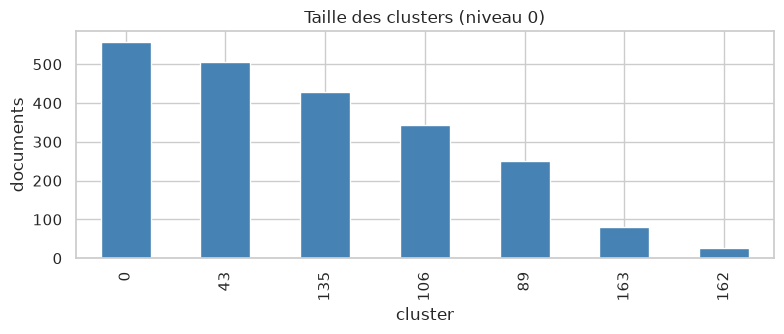

In [15]:
# --- qualité du partitionnement
part0 = [set(df.loc[df.cluster_l0 == c, "doc_id"]) for c in sorted(df.cluster_l0[df.cluster_l0 >= 0].unique())]
mod0 = nx.community.modularity(G, part0, weight="weight")
mk = df.cluster_final >= 0
nmi = normalized_mutual_info_score(df.loc[mk, "dominant_topic"], df.loc[mk, "cluster_final"])
purity = (df[mk].groupby("cluster_final")["dominant_topic"]
          .agg(lambda s: s.value_counts().iloc[0]).sum() / mk.sum())
print(f"Modularité (niveau 0) : {mod0:.3f} | NMI vs thèmes : {nmi:.3f} | pureté vs thèmes : {purity:.3f}")
plt.figure(figsize=(8, 3.5))
df.loc[df.cluster_l0 >= 0, "cluster_l0"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Taille des clusters (niveau 0)"); plt.xlabel("cluster"); plt.ylabel("documents")
plt.tight_layout(); plt.show()

> **Interprétation.** La **modularité de 0,44** indique une structure en communautés nette (au-dessus du seuil usuel de 0,3). Le NMI de 0,23 avec les thèmes LDA est faible : les clusters regroupent par sujet fin et entités partagées plutôt que par thème générique, ce qui n'est pas un défaut. La pureté (0,46) est gonflée par le grand nombre de petits clusters.

## 9. Threat Mapping : description des clusters
Pour chaque cluster : termes dominants, thème majoritaire, et entités par type (vecteurs → malwares → logiciels/cibles).

In [16]:
tf_user = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5, ngram_range=(1, 2))
Xu = tf_user.fit_transform(df["user_txt"])
vocab = np.array(tf_user.get_feature_names_out())

def top_ents(sub, label, k=4):
    c = Counter(t for s in sub["entities"] for (t, l) in s if l == label and (t, l) in ent2id)
    return ", ".join(t for t, _ in c.most_common(k))

def describe(col):
    out = []
    for cid, sub in df[df[col] >= 0].groupby(col):
        if len(sub) < 3: continue
        mean = np.asarray(Xu[sub.index].mean(0)).ravel()
        out.append({
            col: cid, "taille": len(sub),
            "thème majoritaire": sub["dominant_topic"].value_counts().index[0],
            "termes": ", ".join(vocab[mean.argsort()[::-1][:6]]),
            "VECTEUR": top_ents(sub, "VECTEUR"), "MALWARE": top_ents(sub, "MALWARE"),
            "OUTIL": top_ents(sub, "OUTIL"), "SOFTWARE": top_ents(sub, "SOFTWARE"),
            "CIBLE": top_ents(sub, "CIBLE", 3), "ACTEUR": top_ents(sub, "ACTEUR", 3), "CVE": top_ents(sub, "CVE", 3),
        })
    return pd.DataFrame(out).sort_values("taille", ascending=False)

pd.set_option("display.max_colwidth", 60)
cluster_table = describe("cluster_final")
display(cluster_table.head(15))

,cluster_final,taille,thème majoritaire,termes,VECTEUR,MALWARE,OUTIL,SOFTWARE,CIBLE,ACTEUR,CVE
33,46,44,T10 · vulnerability / application / exploit,"including, techniques, heap, stack, multi, dynamic","social engineering, xss, sql injection, remote code exec...","qakbot, ryuk, emotet, dridex","ida pro, wireshark, nmap, ghidra","windows, dns, sql server, wi-fi","bank, banking, iot devices",,
95,118,40,T7 · attack / exploit / implementation,"firmware, uefi, intel, usb, spi flash, flash","privilege escalation, buffer overflow, ransomware, zero-day",,"volatility, ida pro, responder, ghidra","bluetooth, exchange, linux, macos","manufacturing, critical infrastructure, iot devices",,
76,97,40,T11 · researcher / analysis / communication,"threat, intelligence, threat intelligence, ioc, using, a...","lateral movement, privilege escalation, phishing, zero-day",stuxnet,"shodan, yara","ssl, exchange, tls, dns","government, critical infrastructure, military",apt1,
29,39,40,T10 · vulnerability / application / exploit,"lfi, php, file, lfi vulnerability, vulnerability, rce","remote code execution, rce, path traversal, sql injection",,metasploit,"php, http, apache, linux",,,
31,41,39,T10 · vulnerability / application / exploit,"jwt, oauth, token, id_token, flow, server","man-in-the-middle, remote code execution, phishing, csrf",,hashcat,"http, exchange, azure, tls","iot devices, healthcare, e-commerce",,
68,87,38,T2 · detection / implement / evade,"dll, hijacking, dll hijacking, loading, dll loading, win...","dll hijacking, social engineering, privilege escalation,...",stuxnet,"metasploit, ida pro","windows, powershell, http, linux",,,
120,148,38,T2 · detection / implement / evade,"iot, devices, iot devices, botnet, mitm, iot botnets","ddos, man-in-the-middle, supply chain attack, brute force",mirai,"wireshark, metasploit, nmap, shodan","bluetooth, ssh, tls, ssl","iot devices, critical infrastructure, industrial control...",,
7,11,38,T10 · vulnerability / application / exploit,"web, attack, exploitation, using, payload, create","remote code execution, arp spoofing, deserialization, wa...",,"nmap, wireshark, aircrack-ng, volatility","http, linux, oracle, postgresql","critical infrastructure, manufacturing",,
3,5,36,T10 · vulnerability / application / exploit,"session, cookie, parameter, hpp, vulnerability, xss vuln...","xss, cross-site scripting, phishing, csrf",,burp suite,"http, php, dns, ssl",banking,,
110,137,34,T1 · attack / implement / session,"ddos, distributed, sdn, using, design, flow","ddos, brute force, ransomware, arp spoofing","qbot, mirai",,"dns, tls, exchange, apache","critical infrastructure, military, government",,


> **Interprétation.** Les clusters sont **lisibles et cohérents** : firmware et UEFI, JWT / OAuth, DLL hijacking, botnets IoT (*mirai*), canaux C2 dissimulés dans DNS, SSRF, CSRF, élévation de privilèges, LFI / PHP — avec leurs vecteurs, outils et secteurs ciblés. C'est le résultat le plus solide de cette partie et la base du *threat mapping*. Les colonnes d'entités restent partiellement bruitées (*exchange* compte aussi les « key exchange », *phishing* apparaît dans de nombreux clusters) : ce sont des groupes thématiques de documents, pas des campagnes d'attaque.

## 10. Visualisation topologique interactive (PyVis)
Documents colorés par cluster (niveau 0), entités en losanges colorés par type, arêtes `MENTIONNE` (gris) et `SIMILAIRE_A` (orange, épaisseur = score).
Le graphe est limité aux `MAX_DOCS` documents les plus connectés pour rester lisible.

In [17]:
from pyvis.network import Network
from IPython.display import IFrame, display as ipy_display

PALETTE = ["#e6550d", "#3182bd", "#31a354", "#756bb1", "#de2d26", "#636363",
           "#e7ba52", "#17becf", "#8c564b", "#e377c2", "#bcbd22", "#7f7f7f"]
ENT_COL = {"CVE": "#d62728", "IP": "#9467bd", "SOFTWARE": "#2ca02c", "MALWARE": "#000000", "VECTEUR": "#ff7f0e",
           "OUTIL": "#8c564b", "CIBLE": "#17becf", "ACTEUR": "#e377c2", "ATTACK": "#bcbd22", "HASH": "#7f7f7f"}

def build_viz(path=FIG_DIR / "graphe_gtn_leiden.html", max_docs=400, cluster_col="cluster_l0", color_by_pred=False):
    deg = dict(G.degree(weight="weight"))
    docs = sorted(deg, key=deg.get, reverse=True)[:max_docs]
    dset = set(docs)
    net = Network(height="800px", width="100%", bgcolor="#ffffff", font_color="black",
                  directed=False, cdn_resources="remote")
    net.barnes_hut(gravity=-5000, spring_length=120)
    pred_color = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(classes)}
    for i in docs:
        r = df.loc[i]
        col = pred_color[r.pred_hgt] if color_by_pred else PALETTE[int(r[cluster_col]) % len(PALETTE)]
        title = (f"<b>Doc {i}</b><br>Cluster L0 : {r.cluster_l0} | final : {r.cluster_final}"
                 f"<br>Thème (pseudo-label) : {r.dominant_topic}<br>Prédit HGT : {r.pred_hgt}"
                 f"<br><i>{r.user_txt[:140]}</i>")
        net.add_node(f"d{i}", label=str(i), size=10 + 2 * min(deg[i], 6), color=col, title=title)
    ent_used = Counter()
    Bcsr = B.tocsr()
    for i in docs:
        for j in Bcsr[i].indices:
            ent_used[j] += 1
    for j, c in ent_used.items():
        if c < 2: continue
        t, l = ent_list[j]
        net.add_node(f"e{j}", label=t, shape="diamond", size=12 + 3 * min(c, 8),
                     color=ENT_COL.get(l, "#999999"), title=f"<b>{t}</b> ({l})<br>{c} documents affichés")
    for i in docs:
        for j in Bcsr[i].indices:
            if ent_used[j] >= 2:
                net.add_edge(f"d{i}", f"e{j}", color="#bbbbbb", width=0.5, title="MENTIONNE")
    Sc2 = S.tocsr()
    for i in docs:
        for j, s in zip(Sc2[i].indices, Sc2[i].data):
            if j in dset and i < j:
                net.add_edge(f"d{i}", f"d{j}", color="#f4a261", width=1 + 3 * float(s),
                             title=f"SIMILAIRE_A (cosinus={s:.2f})")
    net.write_html(str(path))
    return os.path.relpath(path, Path.cwd())

html_path = build_viz()
ipy_display(IFrame(html_path, width="100%", height=820))

> **Interprétation.** À vérifier visuellement : les documents d'une même couleur doivent former des groupes compacts, et les entités très fréquentes (losanges) servent de ponts entre clusters. Les arêtes orange (`SIMILAIRE_A`) renforcent la cohésion à l'intérieur des clusters, les arêtes grises (`MENTIONNE`) relient les clusters entre eux. Une capture d'écran avec ces observations peut servir de figure dans le rapport.

## 11. Exports pour l'équipe
- `artifacts/notebook2b/doc_clusters.csv` : doc_id (nœud), corpus_id (identifiant d'équipe), clusters Leiden (niveau 0 et final), thème, prédiction HGT.
- `artifacts/notebook2b/hgt_doc_embeddings.npy` : embeddings de documents (réutilisables par le Membre 5).
- `artifacts/notebook2b/cluster_table.csv` et `reports/metrics/notebook2b_metrics.json` (lu par le notebook maître et le MVP).

In [18]:
df[["doc_id", "corpus_id", "user", "dominant_topic", "pred_hgt", "cluster_l0", "cluster_final"]].to_csv(
    OUT_DIR / "doc_clusters.csv", index=False)
np.save(OUT_DIR / "hgt_doc_embeddings.npy", emb_doc)
cluster_table.to_csv(OUT_DIR / "cluster_table.csv", index=False)
metrics = {"classification_test": res,
           "robustness_5_seeds": summary.reset_index().to_dict(orient="records"),
           "leiden": {"modularity_l0": mod0, "nmi_vs_topics": nmi, "purity_vs_topics": purity,
                      "clusters_l0": int(df.loc[df.cluster_l0 >= 0, "cluster_l0"].nunique()),
                      "clusters_final": int(df.loc[df.cluster_final >= 0, "cluster_final"].nunique())},
           "graph": {"docs": N, "entities": M, "mentionne_edges": int(B.nnz), "similaire_edges": int(S.nnz // 2)}}
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
(config.METRICS_DIR / "notebook2b_metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
print(json.dumps(metrics, indent=2, default=float))

{
  "classification_test": {
    "Baseline TF-IDF+SVD + LogReg": {
      "macro_f1": 0.3167363138821643,
      "acc": 0.36363636363636365
    },
    "HGT (entit\u00e9s seules)": {
      "macro_f1": 0.14673946568494287,
      "acc": 0.18787878787878787,
      "best_val_f1": 0.22159982848775653
    },
    "HGT (entit\u00e9s + similarit\u00e9)": {
      "macro_f1": 0.21345472087139294,
      "acc": 0.22727272727272727,
      "best_val_f1": 0.21410111864527157
    }
  },
  "robustness_5_seeds": [
    {
      "mod\u00e8le": "Baseline TF-IDF+SVD + LogReg",
      "mean": 0.322,
      "std": 0.023
    },
    {
      "mod\u00e8le": "HGT (entit\u00e9s + similarit\u00e9)",
      "mean": 0.183,
      "std": 0.015
    },
    {
      "mod\u00e8le": "HGT (entit\u00e9s seules)",
      "mean": 0.158,
      "std": 0.011
    }
  ],
  "leiden": {
    "modularity_l0": 0.4430497982256431,
    "nmi_vs_topics": 0.23303990060719507,
    "purity_vs_topics": 0.45964432284541723,
    "clusters_l0": 7,
    "cluste

## 12. Conclusion

- **Classification** : sur 5 seeds, baseline texte 0,322 ± 0,023 vs HGT 0,183 ± 0,015 (entités + similarité) : **absence de gain** du Graph Transformer sur ces pseudo-labels, conclusion convergente avec le Notebook 2A.
- **Relations non locales** : l'occlusion montre un effet surtout local (≤ 0,04 hors documents concernés) ; elle mesure l'influence des entités, pas les poids d'attention de HGT.
- **Clustering** : modularité 0,44, 7 familles et 149 groupes fins ; les clusters forment une cartographie thématique exploitable (firmware, OAuth/JWT, C2 DNS, botnets IoT, SSRF…).
- **Intégration** : entités du NER de Walid et thèmes LDA du Notebook 1, même `corpus_id` ; exports `doc_clusters.csv`, `hgt_doc_embeddings.npy`, `cluster_table.csv` et métriques pour le notebook maître et le MVP.
- **Limites** : pseudo-labels LDA génériques, entités non validées manuellement, corpus pédagogique, cadre transductif.
- **Pistes** : labels métier annotés, relations validées (CVE → logiciel), filtrage des hubs (`ENT_MAX_FRAC` plus bas), `graspologic` pour le Leiden hiérarchique de référence.